# Catching unsupported sentences: NLI faithfulness checks for RAG answers

A RAG answer can cite a passage and still say something the passage does not support. This notebook checks every sentence of 280 recorded answers against the passages it cites, with a DeBERTa-v3 natural language inference (NLI) model, and separates two failure modes: sentences that cite nothing, and sentences whose citation does not back them up. You get a sentence splitter that keeps citation tags, a windowed NLI scorer, faithfulness per system with bootstrap intervals, and a look at how much of a "verification" gain comes from withholding answers.

Data: the [VeriDex RAG corpus](https://www.kaggle.com/datasets/swapnilshukla007/veridex-rag-corpus) dataset. The answers are cached outputs that the VeriDex pipeline recorded for 56 CS / AI test questions (generators qwen2.5:3b and gpt-oss-120b); no language model is called here. Run time: 27 minutes on a 4-thread laptop CPU shared with other jobs, nearly all of it NLI scoring. No GPU needed; internet is used to download `nli-deberta-v3-base`.

Links: [live app](https://swapnil007-curious.github.io/VeriDex/) · [GitHub repo](https://github.com/Swapnil007-Curious/VeriDex) · paper (link to be added)

Part 3 of the 5-part VeriDex series on building and checking a RAG system.

## Contents

1. Setup
2. The cached answers
3. Splitting answers into cited sentences
4. A windowed NLI scorer
5. Scoring every sentence
6. Does this reproduce the recorded scores?
7. Faithfulness per system
8. Cited and uncited sentences
9. How the threshold moves the numbers
10. Faithful is not the same as correct
11. What we found

## 1. Setup

In [1]:
import importlib.util
import subprocess
import sys


def ensure(package: str, module: str) -> None:
    """Install a pinned package only when the environment does not already provide the module."""
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)


ensure("sentence-transformers==6.2.0", "sentence_transformers")

In [2]:
import json
import os
import random
import re
import time
import warnings
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # keep library notices out of the outputs

In [3]:
SEED = 42  # seeds Python, NumPy and PyTorch; also the bootstrap generator
NLI_MODEL = "cross-encoder/nli-deberta-v3-base"  # 184M-parameter DeBERTa-v3 cross-encoder trained on SNLI and MultiNLI
THRESHOLD = 0.5  # a sentence is supported when P(entailment) >= 0.5 for one of its cited passages
WINDOW_TOKENS, WINDOW_STRIDE = 400, 300  # long passages are split into overlapping windows; the max counts
NLI_BATCH = 16  # pairs per forward pass
N_BOOT = 1000  # bootstrap resamples
SYSTEMS = ["G1", "G2", "G3", "G4", "G2H"]
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Okabe-Ito colours, distinguishable with the common forms of colour blindness
PALETTE = dict(zip(SYSTEMS, ["#E69F00", "#56B4E9", "#009E73", "#0072B2", "#D55E00"]))
SUPPORT_COLOURS = {"cited, supported": "#0072B2", "cited, not supported": "#56B4E9",
                   "uncited, context supports it": "#E69F00", "uncited, nothing supports it": "#D55E00"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})


def set_seed(seed: int = SEED) -> None:
    """Seed every random number generator the notebook touches."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def takeaway(text: str) -> None:
    """Show the one-line conclusion under a plot."""
    display(Markdown(f"> {text}"))


set_seed()
NOTEBOOK_START = time.time()
print(f"device: {DEVICE}, torch {torch.__version__}")

device: cpu, torch 2.15.0+cpu


## 2. The cached answers

These answers were generated earlier by the VeriDex pipeline and are stored in the dataset; this notebook only re-checks them. All five systems retrieve from the same three textbooks and answer the same 56 test questions (40 answerable, 16 not answerable from the books). Each answer cites its passages with tags such as `[C2]`, and each record keeps the passages that were in the prompt.

| system | generator | retrieval | what else happens |
|---|---|---|---|
| G1 | qwen2.5:3b | fixed 512-token chunks, dense bge-base | nothing (naive RAG) |
| G2 | qwen2.5:3b | structure-aware chunks, dense bge-small | nothing |
| G3 | qwen2.5:3b | as G2 | guards: an answer with an uncited sentence or a number not found in its passages becomes an abstention |
| G4 | qwen2.5:3b | as G2 | guards plus a critic model with one revision round |
| G2H | gpt-oss-120b | as G2 | nothing (a larger generator) |

In [4]:
def find_data_dir() -> Path:
    """Locate the veridex-rag-corpus dataset under /kaggle/input (or VERIDEX_DATA_DIR when run elsewhere)."""
    if os.environ.get("VERIDEX_DATA_DIR"):
        return Path(os.environ["VERIDEX_DATA_DIR"])
    for manifest in Path("/kaggle/input").glob("**/MANIFEST.json"):
        if json.loads(manifest.read_text(encoding="utf-8")).get("dataset") == "veridex-rag-corpus":
            return manifest.parent
    raise FileNotFoundError("Add the veridex-rag-corpus dataset to this notebook (Add Input).")


def read_jsonl(path: Path) -> list[dict]:
    """Read a JSON-lines file into a list of dicts."""
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


DATA_DIR = find_data_dir()
WORK_DIR = Path(os.environ.get("VERIDEX_WORK_DIR", "/kaggle/working"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

answers = read_jsonl(DATA_DIR / "cached_answers" / "cs_ai_test_answers.jsonl")
questions = {q["uid"]: q for q in read_jsonl(DATA_DIR / "questions" / "questions.jsonl")}
texts = {p.stem: p.read_text(encoding="utf-8") for p in (DATA_DIR / "text").glob("*.txt")}
chunk_by_id = {}
for path in (DATA_DIR / "chunks" / "cs_ai").glob("*.jsonl"):
    for c in read_jsonl(path):
        chunk_by_id[c["chunk_id"]] = c


def premise_of(chunk_id: str) -> str:
    """The passage text the NLI model reads: heading path, newline, the chunk's text in the document."""
    c = chunk_by_id[chunk_id]
    return f"{c['heading_path']}\n{texts[c['doc_id']][c['char_start']:c['char_end']]}"


overview = pd.DataFrame(answers).assign(answerable=lambda d: d.uid.map(lambda u: questions[u]["answerable"]))
pd.crosstab([overview.system, overview.answerable], overview.outcome).reindex(SYSTEMS, level=0)

outcome            abstained  answered
system answerable                     
G1     False              16         0
       True               10        30
G2     False              16         0
       True                8        32
G3     False              16         0
       True               18        22
G4     False              16         0
       True               22        18
G2H    False              16         0
       True                4        36

## 3. Splitting answers into cited sentences

Faithfulness is measured per sentence, so the splitter decides what gets checked. It has to keep the citation tags that end a sentence (`... in the index. [C2]`), avoid breaking after abbreviations such as "e.g." or "s.", and treat bullet points as sentences. This is a port of the VeriDex splitter.

In [5]:
CITATION_GROUP_RE = re.compile(r"\[\s*[Cc]\s*\d+(?:\s*[,;]\s*(?:[Cc]\s*)?\d+)*\s*\]")
_ABBREVIATIONS = frozenset("rs no nos s ss r rr sec secs cl art arts sub vs v viz e.g i.e eg ie mr mrs ms dr govt ltd co inc para paras ch sch u/s approx fig p pp".split())
_END_RE = re.compile(r"[.!?]+[\"'”’)\]]*(?P<cites>(?:\s*" + CITATION_GROUP_RE.pattern + r")*)(?=\s+[\"'“‘(A-Z0-9]|\s*$)")
_BULLET_RE = re.compile(r"^\s*(?:[-*•]|\d{1,2}[.)])\s+")
_WORD_BEFORE_RE = re.compile(r"([A-Za-z][A-Za-z./]*)$")


@dataclass
class Sentence:
    text: str  # citation tags removed
    labels: list = field(default_factory=list)  # cited labels in order, e.g. ['C2', 'C1']


def labels_in(text: str) -> list:
    """Citation labels in order of first appearance."""
    out = []
    for group in CITATION_GROUP_RE.findall(text):
        for num in re.findall(r"\d+", group):
            if f"C{int(num)}" not in out:
                out.append(f"C{int(num)}")
    return out


def strip_citations(text: str) -> str:
    """Remove citation tags and tidy the spaces they leave."""
    out = re.sub(r"\s+([.,;:!?])", r"\1", CITATION_GROUP_RE.sub("", text))
    return re.sub(r"\s+", " ", out).strip()


def _split_line(line: str) -> list:
    parts, start = [], 0
    for m in _END_RE.finditer(line):
        w = _WORD_BEFORE_RE.search(line[start:m.start()])
        word = w.group(1).lower().rstrip(".") if w else ""
        if word in _ABBREVIATIONS or (len(word) == 1 and word.isalpha()):
            continue
        if line[start:m.end()].strip():
            parts.append(line[start:m.end()].strip())
        start = m.end()
    if line[start:].strip():
        parts.append(line[start:].strip())
    return parts


def split_sentences(answer: str) -> list:
    """Sentences of an answer, each with the citation labels that end it."""
    lines = [ln for ln in (_BULLET_RE.sub("", x).strip() for x in answer.replace("\r", "").split("\n")) if ln]
    merged = []
    for ln in lines:  # a line ending with ':' introduces the next one
        if merged and merged[-1].endswith(":"):
            merged[-1] = f"{merged[-1]} {ln}"
        else:
            merged.append(ln)
    pieces = []
    for ln in merged:
        for piece in _split_line(ln):
            if pieces and not strip_citations(piece) and labels_in(piece):
                pieces[-1] = f"{pieces[-1]} {piece}"  # a lone "[C2]" belongs to the previous sentence
            else:
                pieces.append(piece)
    return [Sentence(strip_citations(p), labels_in(p)) for p in pieces if strip_citations(p) or labels_in(p)]


example = next(a for a in answers if a["system"] == "G2" and a["outcome"] == "answered" and len(labels_in(a["answer"])) >= 2)
print(example["answer"][:600], "\n")
for s in split_sentences(example["answer"]):
    print(s.labels, "|", s.text[:110])

The core.editor configuration in Git sets the default text editor used when Git needs a message. It relates to the commit message editing process by configuring the editor that will be used to input the commit message, which is part of the commit process [C1][C2][C3][C4][C5]. 

[] | The core.editor configuration in Git sets the default text editor used when Git needs a message.
['C1', 'C2', 'C3', 'C4', 'C5'] | It relates to the commit message editing process by configuring the editor that will be used to input the comm


## 4. A windowed NLI scorer

The NLI cross-encoder reads a (premise, hypothesis) pair and returns probabilities for contradiction, entailment and neutral. The premise is the cited passage with its heading path; the hypothesis is the answer sentence. Passages longer than 400 tokens are split into windows with a stride of 300 and the highest entailment probability counts, so a supporting line near the end of a long passage is not truncated away. Scores are cached, because the same (passage, sentence) pair appears in several systems.

In [6]:
from sentence_transformers import CrossEncoder

nli = CrossEncoder(NLI_MODEL, device=DEVICE)
ENTAIL = next(int(i) for i, lab in nli.model.config.id2label.items() if "entail" in lab.lower())
print("labels:", nli.model.config.id2label, "-> entailment index", ENTAIL)


def windows(text: str) -> list:
    """Overlapping windows of at most WINDOW_TOKENS model tokens."""
    offsets = nli.tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]
    if len(offsets) <= WINDOW_TOKENS:
        return [text]
    out = []
    for start in range(0, len(offsets), WINDOW_STRIDE):
        end = min(start + WINDOW_TOKENS, len(offsets))
        out.append(text[offsets[start][0]:offsets[end - 1][1]])
        if end == len(offsets):
            return out
    return out


_cache = {}


def entailment(pairs: list) -> list:
    """Max-over-windows P(entailment) for each (premise, hypothesis) pair, computed once per unique pair."""
    todo = [p for p in dict.fromkeys(pairs) if p not in _cache]
    flat, spans = [], []
    for premise, hyp in todo:
        wins = windows(premise)
        spans.append((len(flat), len(flat) + len(wins)))
        flat += [(w, hyp) for w in wins]
    if flat:
        probs = nli.predict(flat, apply_softmax=True, batch_size=NLI_BATCH, show_progress_bar=False)
        probs = np.asarray(probs).reshape(len(flat), -1)[:, ENTAIL]
        for pair, (a, b) in zip(todo, spans):
            _cache[pair] = float(probs[a:b].max())
    return [_cache[p] for p in pairs]


print(entailment([("Git stores data as snapshots of the project over time.", "Git records snapshots."),
                  ("Git stores data as snapshots of the project over time.", "Git stores a list of file-based changes.")]))

labels: {0: 'contradiction', 1: 'entailment', 2: 'neutral'} -> entailment index 1


[0.9958121180534363, 0.004674720112234354]


## 5. Scoring every sentence

For every sentence of every answered record the notebook computes two scores:

- cited support: the maximum entailment over the passages the sentence cites (0 when it cites nothing, or cites a label that was not in the prompt);
- context support: the maximum entailment over all passages in the prompt, cited or not. This tells an uncited but true-to-the-context sentence apart from one that nothing in the prompt supports.

In [7]:
def sentence_rows(rec: dict) -> list:
    """One row per answer sentence with its cited-support and context-support pairs."""
    premises = {c["label"]: premise_of(c["chunk_id"]) for c in rec["context"]}
    rows = []
    for i, s in enumerate(split_sentences(rec["answer"])):
        valid = [lab for lab in s.labels if lab in premises]
        rows.append({"uid": rec["uid"], "system": rec["system"], "i": i, "text": s.text, "labels": valid,
                     "has_citation": bool(valid), "cited_pairs": [(premises[lab], s.text) for lab in valid],
                     "context_pairs": [(p, s.text) for p in premises.values()]})
    return rows


answered = [a for a in answers if a["outcome"] == "answered"]
sent = pd.DataFrame([r for rec in answered for r in sentence_rows(rec)])
all_pairs = [p for ps in sent.cited_pairs for p in ps] + [p for ps in sent.context_pairs for p in ps]
t0 = time.time()
entailment(all_pairs)
print(f"{len(sent)} sentences, {len(set(all_pairs))} unique NLI pairs scored in {time.time() - t0:.0f} s on {DEVICE}")
sent["cited_support"] = [max(entailment(ps), default=0.0) for ps in sent.cited_pairs]
sent["context_support"] = [max(entailment(ps), default=0.0) for ps in sent.context_pairs]
sent["supported"] = sent.cited_support >= THRESHOLD
sent[["system", "text", "labels", "cited_support", "context_support"]].head(8)

179 sentences, 652 unique NLI pairs scored in 1501 s on cpu


,system,text,labels,cited_support,context_support
0,G1,DropoutMLPScratch uses dropout layers after ea...,"[C1, C2]",0.04988,0.049880
1,G1,Design choices in binary tree implementation i...,[],0.00000,0.204815
2,G1,Storing parent pointers can waste space and in...,[],0.00000,0.034156
3,G1,Storing child pointers as separate variables o...,[],0.00000,0.000455
4,G1,These choices impact both space and time compl...,[],0.00000,0.000301
5,G1,"To remove a file using Git, you can use the `g...",[],0.00000,0.002710
6,G1,"For deleting a file locally, you would use the...",[],0.00000,0.001212
7,G1,Git's `git mv` command is used to rename files...,[],0.00000,0.018977


## 6. Does this reproduce the recorded scores?

The dataset also stores the per-sentence entailment probabilities the VeriDex evaluation recorded with the same model and threshold. If the splitter and scorer above match the pipeline, the two should agree up to floating-point noise.

In [8]:
recorded = pd.DataFrame([{"uid": a["uid"], "system": a["system"], "i": i, "recorded_text": s["text"], "recorded_p": s["p_entail"]}
                         for a in answered for i, s in enumerate(a["recorded_eval"]["sentences"])])
both = sent.merge(recorded, on=["uid", "system", "i"], how="outer", indicator=True)
same_split = (both._merge == "both") & (both.text == both.recorded_text)
matched = both[same_split]
diff = (matched.cited_support - matched.recorded_p).abs()
print(f"sentences here: {len(sent)}, recorded: {len(recorded)}, identical sentence text: {same_split.sum()}")
print(f"|P(entail) here - recorded|: median {diff.median():.4f}, 95th percentile {diff.quantile(0.95):.4f}, max {diff.max():.4f}")
print(f"same supported / not supported decision: {((matched.cited_support >= THRESHOLD) == (matched.recorded_p >= THRESHOLD)).mean():.1%}")

sentences here: 179, recorded: 179, identical sentence text: 179
|P(entail) here - recorded|: median 0.0000, 95th percentile 0.0000, max 0.0000
same supported / not supported decision: 100.0%


## 7. Faithfulness per system

Faithfulness of an answer is the share of its sentences that are supported by their citations; the system score is the mean over the questions it answered. Each system answers a different subset of questions, so the intervals below are plain bootstrap intervals of each mean, and comparisons between systems need care: a system that withholds its weaker answers scores higher on the answers it keeps.

In [9]:
def bootstrap_mean(values, n_resamples: int = N_BOOT, seed: int = SEED) -> tuple:
    """Mean and percentile 95% bootstrap interval."""
    v = np.asarray(values, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(v), size=(n_resamples, len(v)))
    boot = v[idx].mean(axis=1)
    return float(v.mean()), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5))


per_answer = sent.groupby(["system", "uid"]).agg(faithfulness=("supported", "mean"), n_sentences=("supported", "size"),
                                                  any_uncited=("has_citation", lambda x: (~x).any())).reset_index()
rows = []
for s in SYSTEMS:
    sub = per_answer[per_answer.system == s]
    m, lo, hi = bootstrap_mean(sub.faithfulness)
    rows.append({"system": s, "answered": len(sub), "of questions": sum(a["system"] == s for a in answers),
                 "faithfulness": m, "ci_low": lo, "ci_high": hi,
                 "answers with an uncited sentence": sub.any_uncited.mean()})
faith = pd.DataFrame(rows).set_index("system")
faith.style.format({"faithfulness": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "answers with an uncited sentence": "{:.0%}"})

,answered,of questions,faithfulness,ci_low,ci_high,answers with an uncited sentence
system,,,,,,
G1,30,56,0.011,0.000,0.033,50%
G2,32,56,0.312,0.156,0.469,31%
G3,22,56,0.455,0.273,0.682,0%
G4,18,56,0.444,0.222,0.668,0%
G2H,36,56,0.343,0.194,0.491,8%


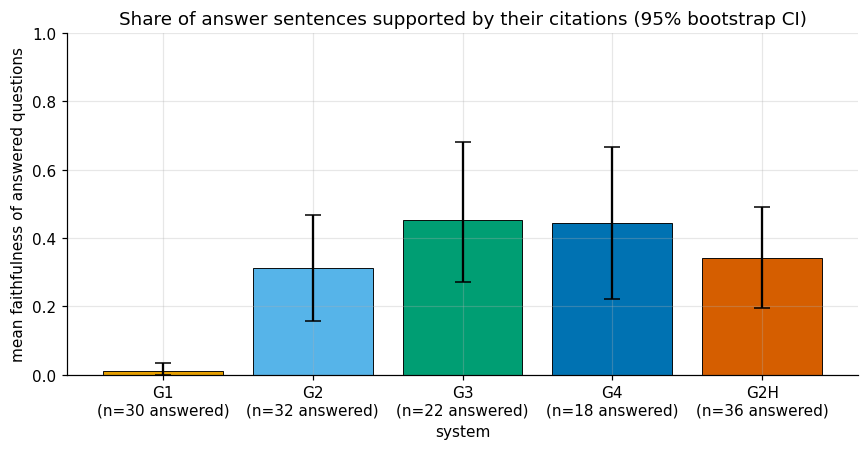

> Faithfulness ranges from 0.01 (G1) to 0.45 (G3), but the systems answered between 18 and 36 of the 56 questions.

In [10]:
def plot_faithfulness(ax, big: bool = False) -> None:
    """Bars of mean faithfulness per system with bootstrap intervals."""
    x = np.arange(len(SYSTEMS))
    ax.bar(x, faith.faithfulness, color=[PALETTE[s] for s in SYSTEMS], edgecolor="black", linewidth=0.6)
    ax.errorbar(x, faith.faithfulness, yerr=[faith.faithfulness - faith.ci_low, faith.ci_high - faith.faithfulness],
                fmt="none", ecolor="black", capsize=5, lw=1.5)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{s}\n(n={faith.loc[s, 'answered']} answered)" for s in SYSTEMS])
    ax.set_ylim(0, 1)
    ax.set_xlabel("system")
    ax.set_ylabel("mean faithfulness of answered questions")


fig, ax = plt.subplots(figsize=(8, 4.2))
plot_faithfulness(ax)
ax.set_title("Share of answer sentences supported by their citations (95% bootstrap CI)")
plt.tight_layout()
plt.show()
takeaway(f"Faithfulness ranges from {faith.faithfulness.min():.2f} ({faith.faithfulness.idxmin()}) to {faith.faithfulness.max():.2f} "
         f"({faith.faithfulness.idxmax()}), but the systems answered between {faith.answered.min()} and {faith.answered.max()} of the 56 questions.")

## 8. Cited and uncited sentences

An unsupported sentence fails in one of two ways. Either it cites nothing, which a simple rule can catch without any model, or it cites a passage that does not back it up, which needs NLI. Splitting the sentences into four groups shows which failure dominates for each system.

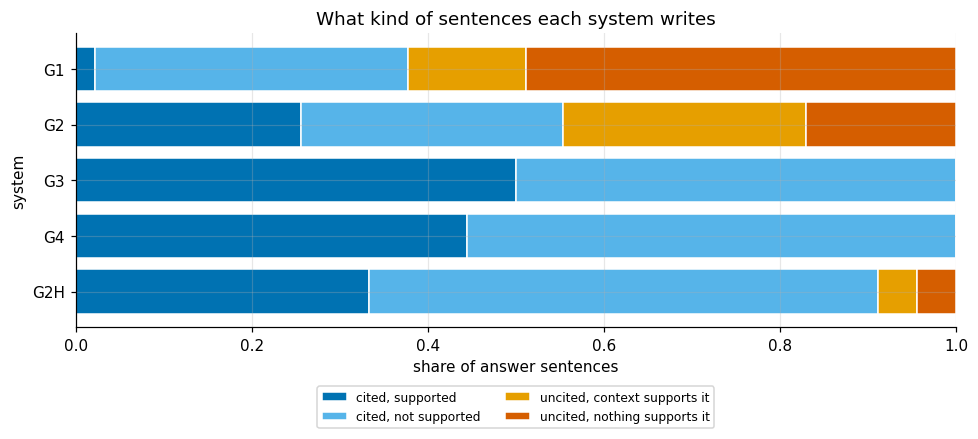

> Uncited sentences make up 45% of G2's sentences and 0% of G4's; the guards in G3 and G4 turn answers with uncited sentences into abstentions.

In [11]:
def support_group(r) -> str:
    if r.has_citation:
        return "cited, supported" if r.supported else "cited, not supported"
    return "uncited, context supports it" if r.context_support >= THRESHOLD else "uncited, nothing supports it"


sent["group"] = sent.apply(support_group, axis=1)
shares = pd.crosstab(sent.system, sent.group, normalize="index").reindex(index=SYSTEMS, columns=list(SUPPORT_COLOURS), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.2))
left = np.zeros(len(SYSTEMS))
for g, colour in SUPPORT_COLOURS.items():
    ax.barh(SYSTEMS, shares[g], left=left, color=colour, edgecolor="white", label=g)
    left += shares[g].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("share of answer sentences")
ax.set_ylabel("system")
ax.set_title("What kind of sentences each system writes")
ax.legend(ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout()
plt.show()
uncited_share = 1 - sent.groupby("system").has_citation.mean()
takeaway(f"Uncited sentences make up {uncited_share.loc['G2']:.0%} of G2's sentences and {uncited_share.loc['G4']:.0%} of G4's; "
         f"the guards in G3 and G4 turn answers with uncited sentences into abstentions.")

Among sentences that do cite something, how often does the citation hold up? This compares the systems on the step NLI actually checks. The interval resamples sentences, which treats sentences of one answer as independent, so it is somewhat too narrow.

In [12]:
cited = sent[sent.has_citation]
rows = []
for s in SYSTEMS:
    m, lo, hi = bootstrap_mean(cited[cited.system == s].supported)
    rows.append({"system": s, "cited sentences": int((cited.system == s).sum()), "supported": m, "ci_low": lo, "ci_high": hi})
cited_support = pd.DataFrame(rows).set_index("system")
cited_support.style.format({"supported": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}"})

,cited sentences,supported,ci_low,ci_high
system,,,,
G1,17,0.059,0.000,0.176
G2,26,0.462,0.269,0.654
G3,24,0.500,0.292,0.708
G4,18,0.444,0.222,0.668
G2H,41,0.366,0.220,0.512


## 9. How the threshold moves the numbers

The 0.5 threshold on P(entailment) is a convention. If the ranking of systems flips as the threshold moves, the comparison is fragile.

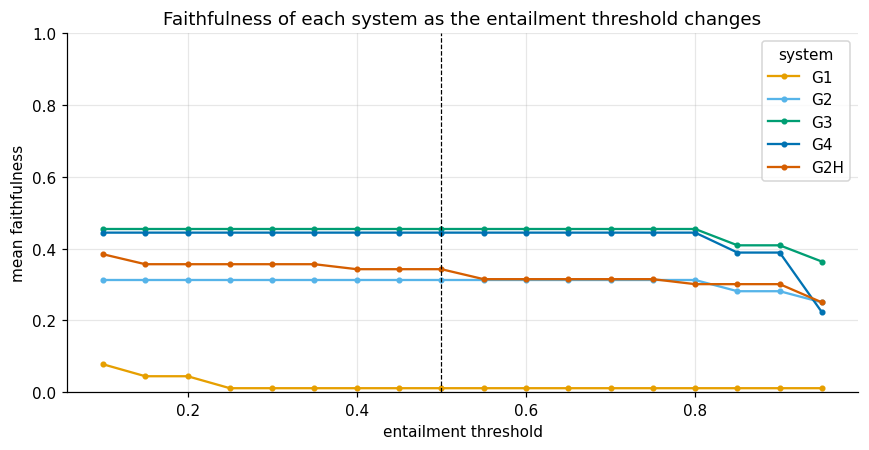

> 34% of cited sentences score above 0.9 and 59% below 0.1, so most decisions do not depend on where between 0.1 and 0.9 the threshold sits.

In [13]:
thresholds = np.round(np.arange(0.1, 0.951, 0.05), 2)
fig, ax = plt.subplots(figsize=(8, 4.2))
for s in SYSTEMS:
    sub = sent[sent.system == s]
    curve = [sub.assign(ok=sub.cited_support >= t).groupby("uid").ok.mean().mean() for t in thresholds]
    ax.plot(thresholds, curve, marker="o", ms=3, color=PALETTE[s], label=s)
ax.axvline(THRESHOLD, color="black", lw=0.8, ls="--")
ax.set_xlabel("entailment threshold")
ax.set_ylabel("mean faithfulness")
ax.set_ylim(0, 1)
ax.set_title("Faithfulness of each system as the entailment threshold changes")
ax.legend(title="system")
plt.tight_layout()
plt.show()
p = sent.cited_support[sent.has_citation]
decisive = (p >= 0.9).mean() + (p <= 0.1).mean()
takeaway(f"{(p >= 0.9).mean():.0%} of cited sentences score above 0.9 and {(p <= 0.1).mean():.0%} below 0.1, so "
         + ("most decisions do not depend on where between 0.1 and 0.9 the threshold sits." if decisive > 0.5
            else "the threshold choice changes the decision for many sentences."))

## 10. Faithful is not the same as correct

A sentence can be entailed by its passage and still fail to answer the question, for example when the retriever brought the wrong passage and the model faithfully summarised it. VeriDex measures correctness separately: the whole answer (tags removed) is the premise and the gold answer the hypothesis. Unanswerable questions are excluded here.

In [14]:
ans_df = pd.DataFrame([{"uid": a["uid"], "system": a["system"], "answer": strip_citations(a["answer"]),
                        "gold": questions[a["uid"]]["gold_answer"]} for a in answered if questions[a["uid"]]["answerable"]])
ans_df["p_correct"] = entailment(list(zip(ans_df.answer, ans_df.gold)))
ans_df["correct"] = ans_df.p_correct >= THRESHOLD
ans_df = ans_df.merge(per_answer, on=["system", "uid"])
ans_df["fully_faithful"] = ans_df.faithfulness == 1.0
grid = pd.crosstab(ans_df.fully_faithful, ans_df.correct).rename(index={True: "every sentence supported", False: "some sentence unsupported"},
                                                                 columns={True: "correct", False: "not correct"})
grid

correct,not correct,correct
fully_faithful,,
some sentence unsupported,50,49
every sentence supported,27,12


A strict NLI check of the whole answer against a one-line gold answer also misses correct answers phrased differently, so "not correct" here is an upper bound on real errors. Notebook 4 uses the same check to decide when a system should abstain.

In [15]:
# Cover image for the Kaggle listing: faithfulness per system at 1280 x 720 pixels
fig, ax = plt.subplots(figsize=(12.8, 7.2), dpi=100)
plot_faithfulness(ax, big=True)
ax.set_title("Share of RAG answer sentences supported by their citations (DeBERTa-v3 NLI)", fontsize=19)
ax.xaxis.label.set_fontsize(15)
ax.yaxis.label.set_fontsize(15)
ax.tick_params(labelsize=14)
fig.tight_layout()
fig.savefig(WORK_DIR / "cover.png", dpi=100)
plt.close(fig)
print(f"notebook run time so far: {(time.time() - NOTEBOOK_START) / 60:.1f} min")

notebook run time so far: 26.4 min


## 11. What we found

In [16]:
ff_correct = int(grid.loc["every sentence supported", "not correct"]) if "every sentence supported" in grid.index and "not correct" in grid.columns else 0
gain_faith = faith.loc["G4", "faithfulness"] - faith.loc["G2", "faithfulness"]
gain_cited = cited_support.loc["G4", "supported"] - cited_support.loc["G2", "supported"]
if gain_faith > 0 and abs(gain_cited) < gain_faith / 2:
    source_of_gain = ("so most of G4's faithfulness gain comes from withholding answers that contained uncited sentences; "
                      "its cited sentences held up about as often as G2's")
elif gain_faith > 0:
    source_of_gain = "so better-supported citations explain part of G4's faithfulness gain as well"
else:
    source_of_gain = "so the guards and critic did not raise faithfulness on this split"
findings = [
    f"Re-scoring {len(sent)} sentences with `{NLI_MODEL}` gave the same supported or unsupported decision as the recorded VeriDex evaluation for "
    f"{((matched.cited_support >= THRESHOLD) == (matched.recorded_p >= THRESHOLD)).mean():.1%} of the sentences whose text matched.",
    f"Mean faithfulness was {faith.loc['G1', 'faithfulness']:.2f} for naive RAG (G1), {faith.loc['G2', 'faithfulness']:.2f} with structure-aware retrieval (G2) "
    f"and {faith.loc['G4', 'faithfulness']:.2f} with guards and a critic (G4), but G4 answered {faith.loc['G4', 'answered']} questions against G2's {faith.loc['G2', 'answered']}.",
    f"Among sentences that cite a passage, the citation held up for {cited_support.loc['G2', 'supported']:.0%} of G2's and {cited_support.loc['G4', 'supported']:.0%} of G4's, "
    f"{source_of_gain}.",
    f"Uncited sentences were {uncited_share.loc['G1']:.0%} of G1's sentences and {uncited_share.loc['G2H']:.0%} of the larger gpt-oss-120b generator's (G2H).",
    f"{ff_correct} of the {int(grid.loc['every sentence supported'].sum()) if 'every sentence supported' in grid.index else 0} answers with every sentence supported "
    f"did not entail the gold answer, a reminder that faithfulness and correctness are separate checks.",
]
display(Markdown("\n\n".join(findings)))

Re-scoring 179 sentences with `cross-encoder/nli-deberta-v3-base` gave the same supported or unsupported decision as the recorded VeriDex evaluation for 100.0% of the sentences whose text matched.

Mean faithfulness was 0.01 for naive RAG (G1), 0.31 with structure-aware retrieval (G2) and 0.44 with guards and a critic (G4), but G4 answered 18 questions against G2's 32.

Among sentences that cite a passage, the citation held up for 46% of G2's and 44% of G4's, so most of G4's faithfulness gain comes from withholding answers that contained uncited sentences; its cited sentences held up about as often as G2's.

Uncited sentences were 62% of G1's sentences and 9% of the larger gpt-oss-120b generator's (G2H).

27 of the 39 answers with every sentence supported did not entail the gold answer, a reminder that faithfulness and correctness are separate checks.

### Limitations

NLI is an automatic proxy for human judgement: DeBERTa trained on SNLI and MultiNLI sees textbook prose and code-heavy passages that differ from its training data, and it scores each sentence alone, so a claim that needs two passages together counts as unsupported. The answers are cached outputs of a fixed pipeline on 56 questions from one collection; with 18 to 36 answered questions per system, the intervals are wide. Systems are compared on different subsets of questions, which is exactly how withholding answers inflates faithfulness.

### Ideas to try

- Replace `NLI_MODEL` with `cross-encoder/nli-deberta-v3-large` or an NLI model trained on longer documents and compare decisions.
- Score each sentence against the concatenation of its cited passages instead of each passage alone.
- Use the context-support score to repair answers: add the missing citation where the context supports an uncited sentence.
- Check your own RAG outputs by building records with `answer` and `context` in the same format.

### The VeriDex series

1. [Chunking legal text for RAG: structure-aware vs fixed vs semantic chunks](https://www.kaggle.com/code/swapnilshukla007/chunking-legal-text-for-rag)
2. [BM25, dense, RRF fusion and cross-encoder reranking: a retrieval ablation you can rerun](https://www.kaggle.com/code/swapnilshukla007/bm25-dense-rrf-and-reranking-rag-ablation)
3. Catching unsupported sentences: NLI faithfulness checks for RAG answers (this notebook)
4. [Teaching a RAG system to abstain: thresholds, coverage and selective accuracy](https://www.kaggle.com/code/swapnilshukla007/teaching-a-rag-system-to-abstain)
5. [RAG in a browser tab: int8 embedding indexes and the size-recall trade-off](https://www.kaggle.com/code/swapnilshukla007/rag-in-a-browser-tab-int8-embedding-indexes)

If you spot a mistake or get different numbers, please say so in the comments; an upvote helps other people find the notebook.